## Profiles with symbolic Python

In [1]:
%pylab inline

Populating the interactive namespace from numpy and matplotlib


In [2]:
from sympy import symbols, diff, simplify

In [3]:
f,v,dvdr,dddt,r=symbols('f v dvdr dddt r')

### Velocity of unperturbed gas

Let's choose this continuous function, with zero derivatives at $r=0$ and $r=1$:

In [4]:
v=simplify(r-r*(1-r)**2+r**2*(1-r))
v

r**2*(3 - 2*r)

At constant density $\rho_0$ this is also the profile of the mass flux $F_\rho = \rho v$ [mass per unit time and area]

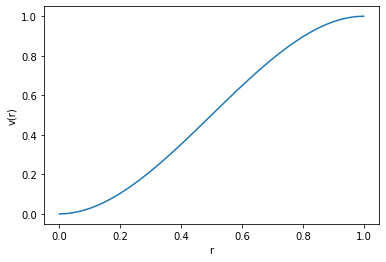

In [5]:
def plot_v():
    r=linspace(0,1)
    plot(r,r**2*(3-2*r))
    xlabel('r'); ylabel('v(r)')
plot_v()

### Mass injection rate

Mass conservation implies that the mass added per unit time and volume is

In [6]:
dddt=simplify(diff(v))
dddt

6*r*(1 - r)

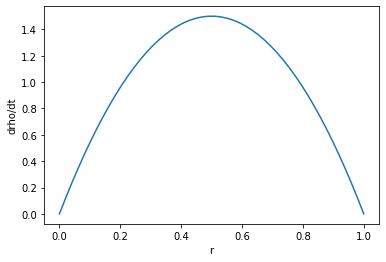

In [7]:
def plot_drho_dt():
    r=linspace(0,1)
    plot(r,6*r*(1-r)); xlabel('r'); ylabel('drho/dt')
plot_drho_dt()

### Momentum injection rate

The equation of motion of gas with a force $f(r)$ is  $\partial v/\partial t + \partial v / \partial r = f(r)$, so for a steady $v(r)$

In [8]:
f=simplify(v*diff(v))
f

6*r**3*(r - 1)*(2*r - 3)

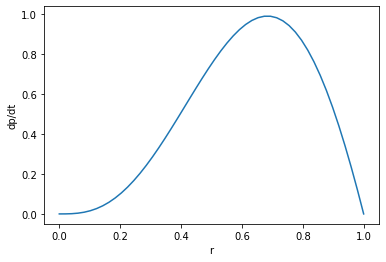

In [9]:
def plot_dp_dt():
    r=linspace(0,1)
    plot(r,6*r**3*(r-1)*(2*r-3)); xlabel('r'); ylabel('dp/dt')
plot_dp_dt()

## Summary of injection equations

Mass injection, with proper scaling units:
$$ \frac{\partial\rho}{\partial t} = \frac{\rho_0 v_0 }{R_0} \, 6 r \, (1-r) $$
where $v_0$ is the terminal speed, $r = R/R_0$, and
$$ \rho_0 = \frac{\dot{M}_{wind}}{4 \pi R_0^2 v_0}$$.

Momentum injection:
$$ \frac{\partial(\rho u_r)}{\partial t} = \frac{\rho_0 v_0^2 }{R_0} \, 6 r^3 (1-r) (3-2r) = v_0 \frac{\partial\rho}{\partial t} r^2(3-2r)$$

In the unpertubed case (no other external forces), the resulting wind profile is
$$ v(r) = v_0 \, r^2(3-2r)$$